# Análise Exploratória — Inteligência Comercial Geográfica | Ativa Solar

Projeto acadêmico da disciplina de Análise de Dados e BI do UNIPÊ, com orientação do professor Daniel Brandão.

## Intuito

Comparar os 12 municípios do recorte de Pernambuco e Paraíba com dados públicos para apoiar uma triagem inicial de localidades que valha a pena investigar para futuras ações de prospecção da Ativa Solar. A análise é exploratória: não comprova demanda, não identifica clientes da Ativa Solar e não estima vendas ou faturamento.

## Escopo e fontes utilizadas

- **GHI — INPE/LABREN, Atlas Brasileiro de Energia Solar, 2ª edição (2017):** médias diárias anuais e mensais da série histórica 1999–2015, em Wh/m².dia, nas coordenadas das sedes municipais. A resolução espacial é de aproximadamente 0,1° (cerca de 10 km). É referência histórica, não medição de telhados.
- **ANEEL — MMGD fotovoltaica:** instalações, potência instalada em kW e unidades consumidoras com créditos registradas nos municípios; arquivo com referência em 10/11/2026. São dados do mercado local, não clientes, vendas ou faturamento da Ativa Solar.
- **IBGE — Estimativas da População 2026:** habitantes por município, referência em 01/07/2026. População não substitui domicílios.

## Perguntas e limites

Este notebook contribui para a pergunta 3 (GHI anual e mensal) e para a descrição atual da pergunta 4 (instalações e potência ANEEL). As razões por mil habitantes e a dispersão população–instalações são indicadores descritivos que contextualizam a pergunta 5; não formam uma recomendação comercial.

As perguntas 1 e 2 dependem dos domicílios particulares permanentes ocupados do Censo 2022, dos CNAEs definidos com a empresa, da coleta de estabelecimentos ativos e da confirmação dos municípios atendidos. Esses dados continuam pendentes. A evolução anual da ANEEL depende de registros com datas de conexão.

Baixa adoção solar, isoladamente, não prova oportunidade. A base tem somente 12 municípios, e a associação entre população e instalações pode refletir diferenças de escala. Não interpretamos correlação como causalidade.

**Estado das saídas:** este arquivo inclui saídas salvas de execuções anteriores. Uma verificação local da versão atual confirmou que as nove células de código executam sem erro com a base integrada do projeto; execute as células em ordem para recalcular e atualizar as saídas exibidas.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

caminho_relativo = Path("Base de dados/05_bases_tratadas/base_integrada_limpa.csv")
candidatos = [
    Path.cwd() / caminho_relativo,
    Path.cwd().parent / caminho_relativo,
]
caminho_base = next((p for p in candidatos if p.is_file()), None)

parametros_leitura = {
    "sep": ";",
    "decimal": ",",
    "encoding": "utf-8-sig",
    "dtype": {"codigo_ibge": "string"},
}

if caminho_base is not None:
    df_eda = pd.read_csv(caminho_base, **parametros_leitura)
    origem_base = str(caminho_base)
else:
    # No Colab, o reposit?rio local do computador n?o fica montado.
    # Usa uma vers?o fixa da base publicada no GitHub.
    ref_repositorio = "997550f33c5d3ab64bab28af927c2cc444a81220"
    url_base = (
        "https://raw.githubusercontent.com/Pedro-hxm/Analise_de_Dados/"
        f"{ref_repositorio}/Base%20de%20dados/05_bases_tratadas/"
        "base_integrada_limpa.csv"
    )
    try:
        df_eda = pd.read_csv(url_base, **parametros_leitura)
    except Exception as erro:
        raise RuntimeError(
            "N?o foi poss?vel localizar a base tratada no projeto nem carreg?-la "
            "do GitHub. No VS Code, abra o notebook a partir da raiz do projeto; "
            "no Colab, verifique o acesso ? internet e ao reposit?rio."
        ) from erro
    origem_base = f"GitHub, commit {ref_repositorio}"

print(f"Base carregada: {origem_base}")
print(f"Dimens?es: {df_eda.shape[0]} linhas ? {df_eda.shape[1]} colunas")


Base carregada: e:\Analise de dados\Analise_de_Dados\Base de dados\05_bases_tratadas\base_integrada_limpa.csv
Dimensões: 12 linhas × 44 colunas


In [3]:
municipios_esperados = {
    "2500601": ("PB", "Alhandra"),
    "2503001": ("PB", "Caaporã"),
    "2504603": ("PB", "Conde"),
    "2507507": ("PB", "João Pessoa"),
    "2511202": ("PB", "Pedras de Fogo"),
    "2511905": ("PB", "Pitimbu"),
    "2600054": ("PE", "Abreu e Lima"),
    "2606200": ("PE", "Goiana"),
    "2606804": ("PE", "Igarassu"),
    "2607604": ("PE", "Ilha de Itamaracá"),
    "2607653": ("PE", "Itambé"),
    "2607752": ("PE", "Itapissuma"),
}

if len(df_eda) != 12:
    raise ValueError(f"Esperadas 12 linhas municipais; encontradas {len(df_eda)}.")

df_eda["codigo_ibge"] = df_eda["codigo_ibge"].astype("string").str.strip()
df_eda["uf"] = df_eda["uf"].astype("string").str.strip()
df_eda["municipio"] = df_eda["municipio"].astype("string").str.strip()

if not df_eda["codigo_ibge"].str.fullmatch(r"[0-9]{7}", na=False).all():
    raise ValueError("Há código IBGE ausente ou diferente de uma chave textual de sete dígitos.")
if df_eda["codigo_ibge"].nunique(dropna=True) != 12:
    raise ValueError("Os códigos IBGE não são únicos para os 12 municípios.")

identificacoes = set(zip(df_eda["codigo_ibge"], df_eda["uf"], df_eda["municipio"]))
identificacoes_esperadas = {
    (codigo, uf, municipio)
    for codigo, (uf, municipio) in municipios_esperados.items()
}
if identificacoes != identificacoes_esperadas:
    raise ValueError("Os códigos, UFs ou municípios da base divergem do recorte esperado.")

meses = {
    "jan": "Jan", "feb": "Fev", "mar": "Mar", "apr": "Abr",
    "may": "Mai", "jun": "Jun", "jul": "Jul", "aug": "Ago",
    "sep": "Set", "oct": "Out", "nov": "Nov", "dec": "Dez",
}
colunas_analise = [
    "ghi_annual_Wh_m2_day",
    *[f"ghi_{mes}_Wh_m2_day" for mes in meses],
    "gd_fv_instalacoes",
    "gd_fv_potencia_instalada_kw",
    "populacao_estimada_2026",
    "gd_fv_instalacoes_por_1000_hab",
    "gd_fv_kw_por_1000_hab",
]
ausentes = [coluna for coluna in colunas_analise if coluna not in df_eda.columns]
if ausentes:
    raise KeyError(f"Colunas necessárias ausentes na base: {ausentes}")

for coluna in colunas_analise:
    df_eda[coluna] = pd.to_numeric(df_eda[coluna], errors="coerce")
    if df_eda[coluna].isna().any():
        municipios_com_ausencia = df_eda.loc[
            df_eda[coluna].isna(), "municipio"
        ].tolist()
        raise ValueError(
            f"{coluna} contém ausência ou valor inválido em {municipios_com_ausencia}. "
            "A análise não substitui campos vazios por zero."
        )

razao_instalacoes = (
    df_eda["gd_fv_instalacoes"] / df_eda["populacao_estimada_2026"] * 1000
)
razao_potencia = (
    df_eda["gd_fv_potencia_instalada_kw"] / df_eda["populacao_estimada_2026"] * 1000
)
if not (
    razao_instalacoes.round(2)
    == df_eda["gd_fv_instalacoes_por_1000_hab"].round(2)
).all():
    raise ValueError("A razão recalculada de instalações por mil habitantes diverge da base.")
if not (
    razao_potencia.round(2)
    == df_eda["gd_fv_kw_por_1000_hab"].round(2)
).all():
    raise ValueError("A razão recalculada de potência por mil habitantes diverge da base.")

print("Validação concluída: 12 municípios, códigos únicos e indicadores numéricos disponíveis.")


Validação concluída: 12 municípios, códigos únicos e indicadores numéricos disponíveis.


## 1. Ranking da irradiação solar média anual

**Pergunta:** quais municípios têm os maiores valores médios anuais de GHI?

**Fonte:** INPE/LABREN, Atlas Brasileiro de Energia Solar (2017), coluna GHI anual da base integrada. **Unidade:** Wh/m².dia.

**Limitação:** referência histórica de 1999–2015 nas coordenadas das sedes municipais; não descreve cada imóvel, telhado ou geração futura. O ranking usa GHI horizontal e não atribui ângulo específico ao campo GTI.

,municipio,uf,ghi_annual_Wh_m2_day
0,Ilha de Itamaracá,PE,5532
1,João Pessoa,PB,5530
2,Itapissuma,PE,5518
3,Pitimbu,PB,5504
4,Goiana,PE,5451
5,Conde,PB,5449
6,Alhandra,PB,5416
7,Caaporã,PB,5410
8,Itambé,PE,5403
9,Pedras de Fogo,PB,5403


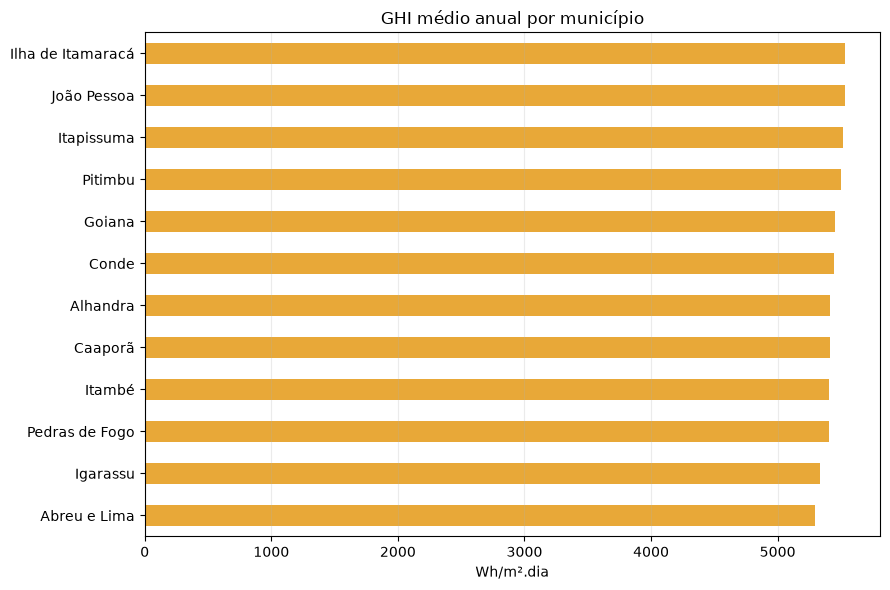

Interpretação: o maior valor é de Ilha de Itamaracá (5,532 Wh/m².dia) e o menor de Abreu e Lima (5,292 Wh/m².dia). É uma diferença entre referências históricas das sedes municipais.


In [4]:
# 1. GHI médio anual por município
col_ghi = "ghi_annual_Wh_m2_day"
ranking_ghi = df_eda[["municipio", "uf", col_ghi]].copy()
ranking_ghi[col_ghi] = pd.to_numeric(ranking_ghi[col_ghi], errors="coerce")
if ranking_ghi[col_ghi].isna().any():
    raise ValueError("Há valores ausentes ou inválidos no GHI anual.")

ranking_ghi = ranking_ghi.sort_values(col_ghi, ascending=False).reset_index(drop=True)
display(ranking_ghi)

ax = ranking_ghi.plot.barh(
    x="municipio", y=col_ghi, legend=False, color="#e8a838", figsize=(9, 6)
)
ax.invert_yaxis()
ax.set_title("GHI médio anual por município")
ax.set_xlabel("Wh/m².dia")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

maior_ghi = ranking_ghi.iloc[0]
menor_ghi = ranking_ghi.iloc[-1]
print(
    f"Interpretação: o maior valor é de {maior_ghi['municipio']} "
    f"({maior_ghi[col_ghi]:,.0f} Wh/m².dia) e o menor de "
    f"{menor_ghi['municipio']} ({menor_ghi[col_ghi]:,.0f} Wh/m².dia). "
    "É uma diferença entre referências históricas das sedes municipais."
)

## 2. Comparação mensal de GHI

**Pergunta relacionada:** como o GHI mensal varia entre as sedes municipais?

Os valores são médias diárias mensais da série histórica do Atlas. A comparação descreve sazonalidade histórica; não é uma medição de telhado nem uma evolução entre anos.


,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
municipio,,,,,,,,,,,,
Alhandra,5748,5984,6002,5293,4701,4291,4339,5142,5553,5877,6015,6049
Caaporã,5746,6018,6004,5306,4648,4264,4333,5109,5549,5871,6031,6045
Conde,5812,5992,6019,5313,4734,4320,4385,5190,5594,5920,6059,6048
João Pessoa,5862,6002,6009,5365,4823,4360,4475,5261,5758,6054,6240,6151
Pedras de Fogo,5740,5940,5925,5335,4628,4243,4356,5058,5592,5849,6132,6035
Pitimbu,5810,6081,6054,5352,4782,4366,4423,5242,5668,6037,6073,6164
Abreu e Lima,5716,5881,5834,5136,4471,4161,4269,4998,5406,5686,5985,5966
Goiana,5806,6119,6042,5300,4657,4280,4374,5139,5546,5930,6096,6124
Igarassu,5770,5931,5969,5162,4483,4170,4290,5019,5405,5729,6037,6034


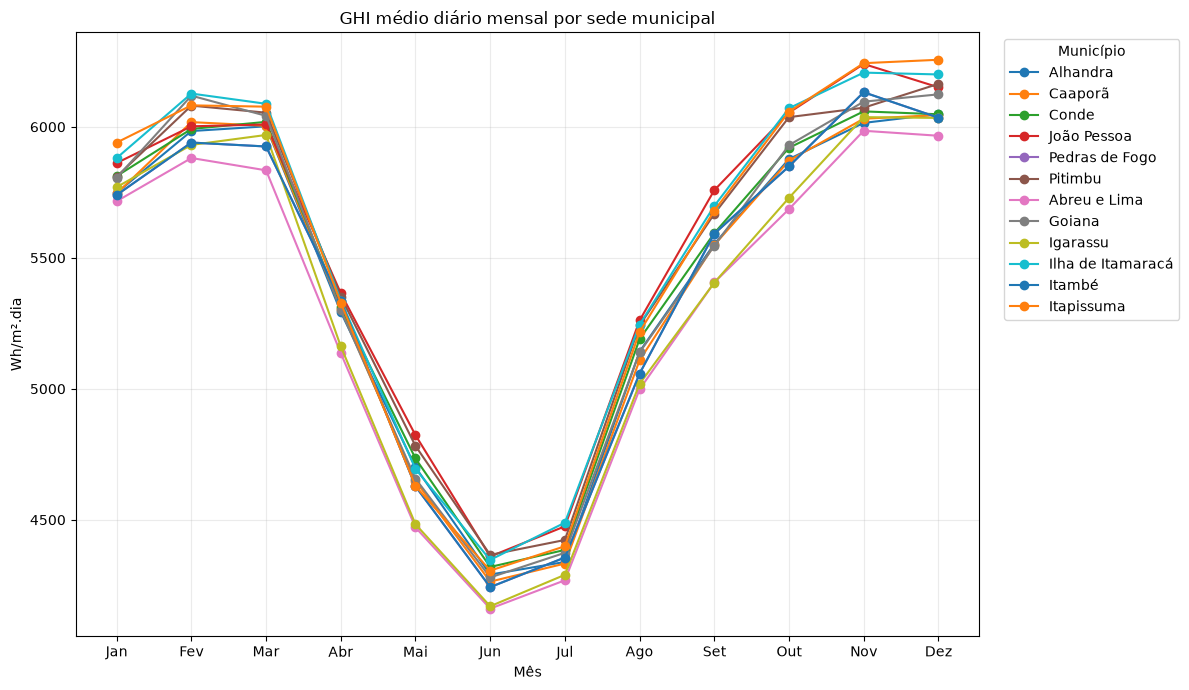

In [5]:
colunas_ghi_mensal = [f"ghi_{mes}_Wh_m2_day" for mes in meses]
ghi_mensal = df_eda.set_index("municipio")[colunas_ghi_mensal].copy()
ghi_mensal.columns = list(meses.values())
display(ghi_mensal)

fig, ax = plt.subplots(figsize=(12, 7))
for municipio in ghi_mensal.index:
    ax.plot(
        list(meses.values()),
        ghi_mensal.loc[municipio],
        marker="o",
        linewidth=1.5,
        label=municipio,
    )

ax.set_title("GHI médio diário mensal por sede municipal")
ax.set_xlabel("Mês")
ax.set_ylabel("Wh/m².dia")
ax.grid(alpha=0.25)
ax.legend(title="Município", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 3. Quantidade de instalações fotovoltaicas

**Pergunta:** como o número de instalações fotovoltaicas registradas pela ANEEL se distribui entre os municípios?

**Fonte:** ANEEL, MMGD fotovoltaica, arquivo com referência de 10/11/2026.  
**Unidade:** instalações.  
**Limitação:** o total descreve a geração distribuída registrada no município; não identifica clientes ou vendas da Ativa Solar. Uma contagem baixa, isoladamente, não comprova demanda não atendida nem maior potencial comercial.

,municipio,uf,gd_fv_instalacoes
0,João Pessoa,PB,10448
1,Goiana,PE,1979
2,Igarassu,PE,1712
3,Abreu e Lima,PE,1227
4,Ilha de Itamaracá,PE,930
5,Conde,PB,898
6,Itambé,PE,301
7,Pedras de Fogo,PB,295
8,Itapissuma,PE,240
9,Pitimbu,PB,231


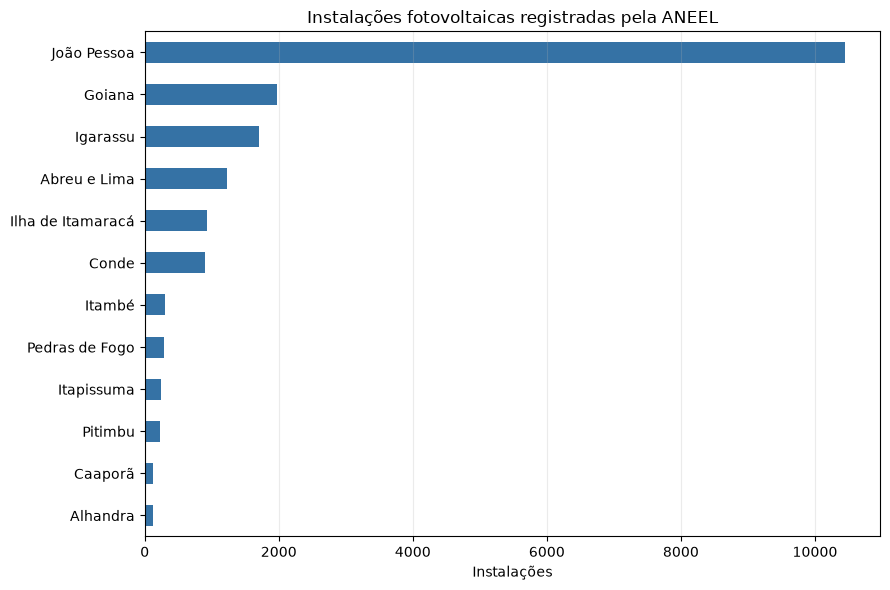

Interpretação: João Pessoa tem o maior total (10,448) e Alhandra o menor (122) entre os 12 municípios.


In [6]:
col_inst = "gd_fv_instalacoes"
instalacoes_municipais = df_eda[["municipio", "uf", col_inst]].copy()
instalacoes_municipais[col_inst] = pd.to_numeric(
    instalacoes_municipais[col_inst], errors="coerce"
)
if instalacoes_municipais[col_inst].isna().any():
    raise ValueError("Há valores ausentes ou inválidos na contagem de instalações.")

instalacoes_municipais = instalacoes_municipais.sort_values(
    col_inst, ascending=False
).reset_index(drop=True)
display(instalacoes_municipais)

ax = instalacoes_municipais.plot.barh(
    x="municipio", y=col_inst, legend=False, color="#3572a5", figsize=(9, 6)
)
ax.invert_yaxis()
ax.set_title("Instalações fotovoltaicas registradas pela ANEEL")
ax.set_xlabel("Instalações")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

maior = instalacoes_municipais.iloc[0]
menor = instalacoes_municipais.iloc[-1]
print(
    f"Interpretação: {maior['municipio']} tem o maior total "
    f"({maior[col_inst]:,.0f}) e {menor['municipio']} o menor "
    f"({menor[col_inst]:,.0f}) entre os 12 municípios."
)

## 4. Potência fotovoltaica instalada

**Pergunta:** qual é a potência instalada total registrada pela ANEEL em cada município?

**Fonte:** ANEEL, MMGD fotovoltaica, arquivo com referência de 10/11/2026.  
**Unidade:** kW.  
**Limitação:** trata-se da potência da geração distribuída registrada no município. O dado não corresponde a instalações, vendas ou faturamento da Ativa Solar, nem informa por si só a capacidade livre da rede.

,municipio,uf,gd_fv_potencia_instalada_kw
0,João Pessoa,PB,118223.30
1,Goiana,PE,21997.69
2,Igarassu,PE,16256.97
3,Conde,PB,11078.60
4,Abreu e Lima,PE,9856.04
5,Ilha de Itamaracá,PE,8667.67
6,Pedras de Fogo,PB,4731.62
7,Itambé,PE,3503.73
8,Alhandra,PB,2876.87
9,Pitimbu,PB,2334.68


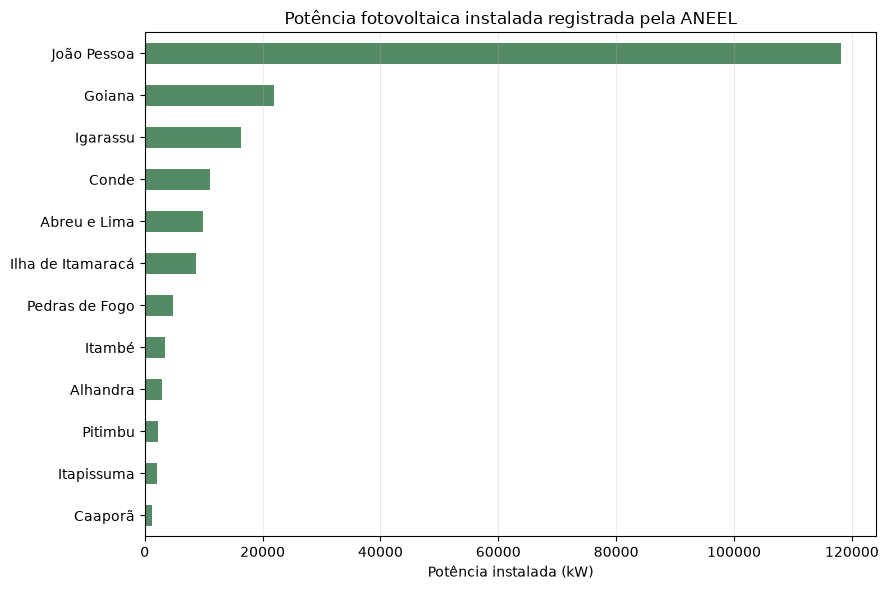

Interpretação: João Pessoa tem a maior potência registrada (118,223.30 kW) e Caaporã a menor (1,213.37 kW).


In [7]:
col_pot = "gd_fv_potencia_instalada_kw"
potencia_municipal = df_eda[["municipio", "uf", col_pot]].copy()
potencia_municipal[col_pot] = pd.to_numeric(potencia_municipal[col_pot], errors="coerce")
if potencia_municipal[col_pot].isna().any():
    raise ValueError("Há valores ausentes ou inválidos na potência instalada.")

potencia_municipal = potencia_municipal.sort_values(
    col_pot, ascending=False
).reset_index(drop=True)
display(potencia_municipal)

ax = potencia_municipal.plot.barh(
    x="municipio", y=col_pot, legend=False, color="#548b65", figsize=(9, 6)
)
ax.invert_yaxis()
ax.set_title("Potência fotovoltaica instalada registrada pela ANEEL")
ax.set_xlabel("Potência instalada (kW)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

maior = potencia_municipal.iloc[0]
menor = potencia_municipal.iloc[-1]
print(
    f"Interpretação: {maior['municipio']} tem a maior potência registrada "
    f"({maior[col_pot]:,.2f} kW) e {menor['municipio']} a menor "
    f"({menor[col_pot]:,.2f} kW)."
)

## 5. Instalações por 1.000 habitantes

**Pergunta:** como varia a quantidade registrada de instalações fotovoltaicas em relação à população municipal estimada?

**Fonte:** ANEEL, MMGD fotovoltaica (10/11/2026), e IBGE, população estimada de 2026.  
**Unidade:** instalações por 1.000 habitantes.  
**Limitação:** razão descritiva calculada com população estimada; não é percentual de domicílios com energia solar, nem taxa de clientes da Ativa Solar. Municípios podem diferir em população, domicílios e composição dos consumidores.

,municipio,uf,gd_fv_instalacoes_por_1000_hab
0,Ilha de Itamaracá,PE,36.08
1,Conde,PB,29.49
2,Goiana,PE,23.06
3,Igarassu,PE,13.84
4,Pitimbu,PB,13.46
5,Abreu e Lima,PE,11.74
6,João Pessoa,PB,11.53
7,Pedras de Fogo,PB,9.35
8,Itambé,PE,8.21
9,Itapissuma,PE,8.04


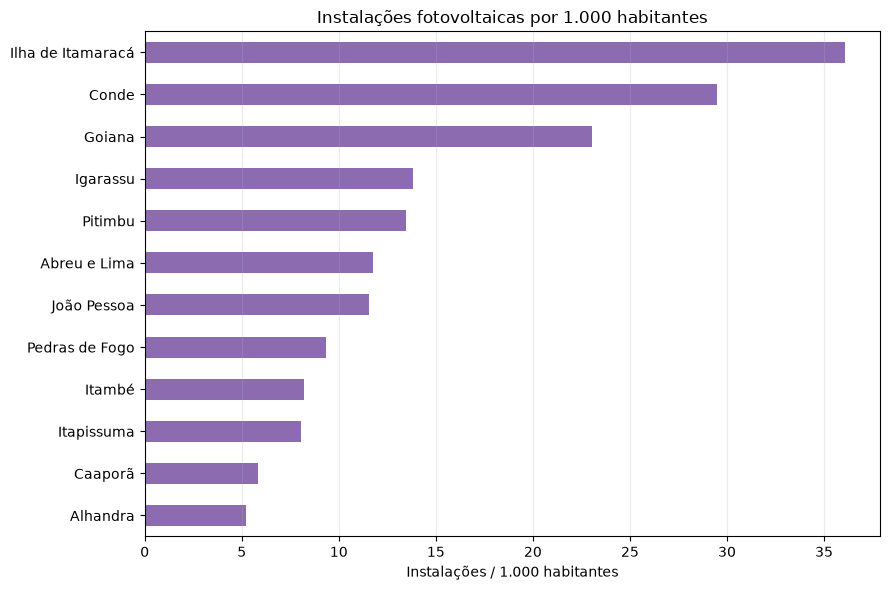

Interpretação: Ilha de Itamaracá apresenta a maior razão (36.08) e Alhandra a menor (5.23) instalações por 1.000 habitantes.


In [8]:
col_inst_1000 = "gd_fv_instalacoes_por_1000_hab"
instalacoes_por_1000 = df_eda[["municipio", "uf", col_inst_1000]].copy()
instalacoes_por_1000[col_inst_1000] = pd.to_numeric(
    instalacoes_por_1000[col_inst_1000], errors="coerce"
)
if instalacoes_por_1000[col_inst_1000].isna().any():
    raise ValueError("Há valores ausentes ou inválidos no indicador de instalações por 1.000 habitantes.")

instalacoes_por_1000 = instalacoes_por_1000.sort_values(
    col_inst_1000, ascending=False
).reset_index(drop=True)
display(instalacoes_por_1000)

ax = instalacoes_por_1000.plot.barh(
    x="municipio", y=col_inst_1000, legend=False, color="#8c6bb1", figsize=(9, 6)
)
ax.invert_yaxis()
ax.set_title("Instalações fotovoltaicas por 1.000 habitantes")
ax.set_xlabel("Instalações / 1.000 habitantes")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

maior = instalacoes_por_1000.iloc[0]
menor = instalacoes_por_1000.iloc[-1]
print(
    f"Interpretação: {maior['municipio']} apresenta a maior razão "
    f"({maior[col_inst_1000]:.2f}) e {menor['municipio']} a menor "
    f"({menor[col_inst_1000]:.2f}) instalações por 1.000 habitantes."
)

## 6. Potência instalada por 1.000 habitantes

**Pergunta:** como varia a potência fotovoltaica registrada pela ANEEL em relação à população municipal estimada?

**Fonte:** ANEEL, MMGD fotovoltaica (10/11/2026), e IBGE, população estimada de 2026.  
**Unidade:** kW por 1.000 habitantes.  
**Limitação:** razão descritiva baseada em totais municipais e população estimada. Não representa consumo, capacidade disponível da rede, potencial de telhados ou desempenho de um sistema específico.

,municipio,uf,gd_fv_kw_por_1000_hab
0,Conde,PB,363.88
1,Ilha de Itamaracá,PE,336.24
2,Goiana,PE,256.37
3,Pedras de Fogo,PB,149.98
4,Pitimbu,PB,135.99
5,Igarassu,PE,131.46
6,João Pessoa,PB,130.48
7,Alhandra,PB,123.38
8,Itambé,PE,95.53
9,Abreu e Lima,PE,94.29


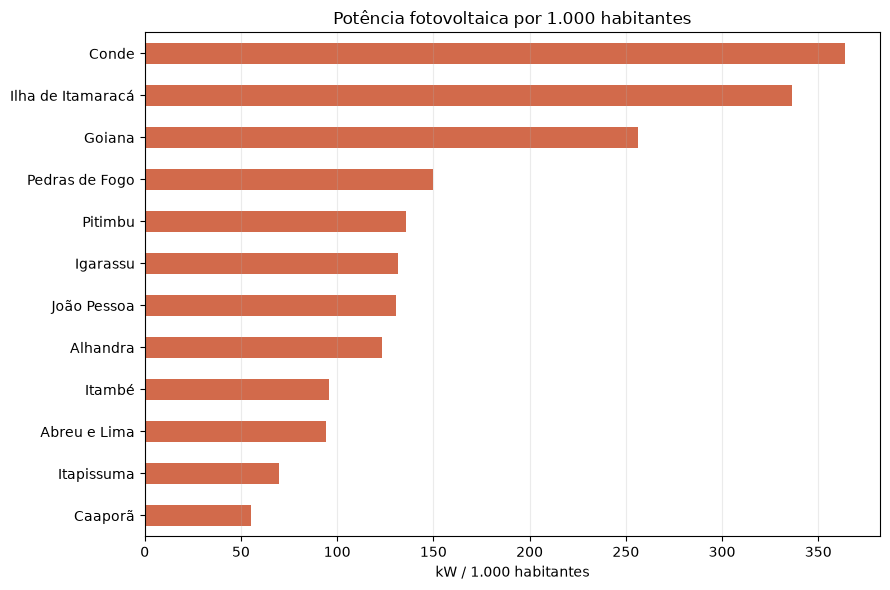

Interpretação: Conde apresenta a maior razão (363.88) e Caaporã a menor (55.12) kW por 1.000 habitantes.


In [9]:
col_kw_1000 = "gd_fv_kw_por_1000_hab"
kw_por_1000 = df_eda[["municipio", "uf", col_kw_1000]].copy()
kw_por_1000[col_kw_1000] = pd.to_numeric(kw_por_1000[col_kw_1000], errors="coerce")
if kw_por_1000[col_kw_1000].isna().any():
    raise ValueError("Há valores ausentes ou inválidos no indicador de potência por 1.000 habitantes.")

kw_por_1000 = kw_por_1000.sort_values(
    col_kw_1000, ascending=False
).reset_index(drop=True)
display(kw_por_1000)

ax = kw_por_1000.plot.barh(
    x="municipio", y=col_kw_1000, legend=False, color="#d26a4b", figsize=(9, 6)
)
ax.invert_yaxis()
ax.set_title("Potência fotovoltaica por 1.000 habitantes")
ax.set_xlabel("kW / 1.000 habitantes")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

maior = kw_por_1000.iloc[0]
menor = kw_por_1000.iloc[-1]
print(
    f"Interpretação: {maior['municipio']} apresenta a maior razão "
    f"({maior[col_kw_1000]:.2f}) e {menor['municipio']} a menor "
    f"({menor[col_kw_1000]:.2f}) kW por 1.000 habitantes."
)

## 7. População estimada e número de instalações

**Pergunta:** como a população municipal estimada se relaciona com a quantidade de instalações fotovoltaicas registrada pela ANEEL?

**Fontes:** IBGE, população estimada de 2026; ANEEL, MMGD fotovoltaica com referência de 10/11/2026.  
**Unidades:** habitantes estimados e instalações.  
**Limitação:** a correlação de Pearson resume associação linear nesta amostra de 12 municípios; não demonstra causalidade. O porte de João Pessoa pode influenciar a associação. Os registros da ANEEL não são clientes da Ativa Solar.

,municipio,uf,populacao_estimada_2026,gd_fv_instalacoes
0,João Pessoa,PB,906093,10448
1,Igarassu,PE,123666,1712
2,Abreu e Lima,PE,104527,1227
3,Goiana,PE,85806,1979
4,Itambé,PE,36677,301
5,Pedras de Fogo,PB,31549,295
6,Conde,PB,30446,898
7,Itapissuma,PE,29859,240
8,Ilha de Itamaracá,PE,25778,930
9,Alhandra,PB,23318,122


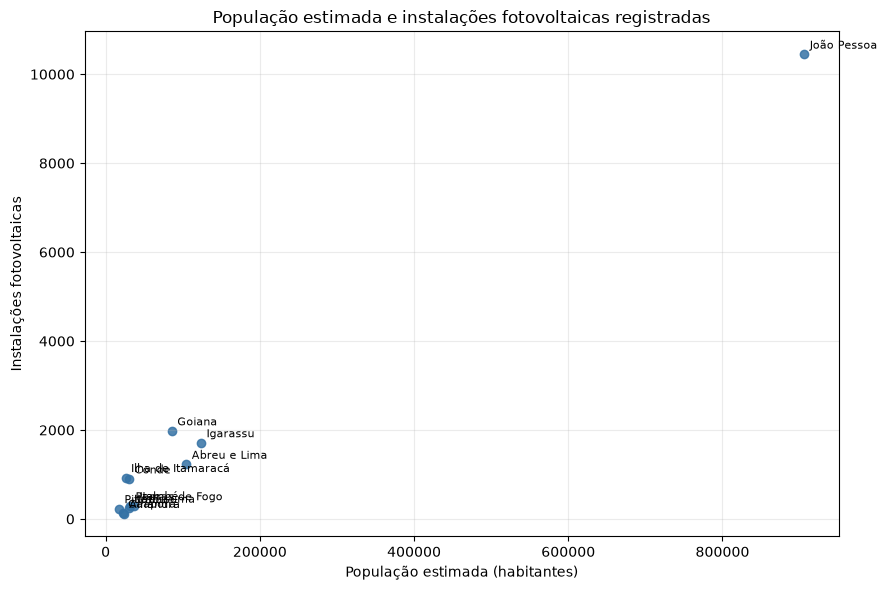

Interpretação: a correlação de Pearson é 0.992, uma associação linear positiva nesta amostra de 12 municípios. A associação é descritiva, pode refletir diferenças de escala e não indica causalidade.


In [10]:
col_pop = "populacao_estimada_2026"
comparacao_pop_inst = df_eda[["municipio", "uf", col_pop, "gd_fv_instalacoes"]].copy()
comparacao_pop_inst[col_pop] = pd.to_numeric(comparacao_pop_inst[col_pop], errors="coerce")
comparacao_pop_inst["gd_fv_instalacoes"] = pd.to_numeric(
    comparacao_pop_inst["gd_fv_instalacoes"], errors="coerce"
)
if comparacao_pop_inst[[col_pop, "gd_fv_instalacoes"]].isna().any().any():
    raise ValueError("Há valores ausentes ou inválidos na população ou nas instalações.")

display(comparacao_pop_inst.sort_values(col_pop, ascending=False).reset_index(drop=True))

correlacao_pearson = comparacao_pop_inst[[col_pop, "gd_fv_instalacoes"]].corr(
    method="pearson"
).iloc[0, 1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    comparacao_pop_inst[col_pop],
    comparacao_pop_inst["gd_fv_instalacoes"],
    color="#3572a5",
    alpha=0.85
)
for _, linha in comparacao_pop_inst.iterrows():
    ax.annotate(
        linha["municipio"],
        (linha[col_pop], linha["gd_fv_instalacoes"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )
ax.set_title("População estimada e instalações fotovoltaicas registradas")
ax.set_xlabel("População estimada (habitantes)")
ax.set_ylabel("Instalações fotovoltaicas")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

sentido = "positiva" if correlacao_pearson >= 0 else "negativa"
print(
    f"Interpretação: a correlação de Pearson é {correlacao_pearson:.3f}, "
    f"uma associação linear {sentido} nesta amostra de 12 municípios. "
    "A associação é descritiva, pode refletir diferenças de escala e não indica causalidade."
)

## O que esta análise não conclui

As análises aqui presentes não respondem onde estão os maiores públicos residencial e empresarial porque os domicílios ocupados, os CNAEs/estabelecimentos ativos e a área atendida continuam pendentes. A pergunta 5 permanece uma lista preliminar para validação comercial; estes indicadores, sozinhos, não sustentam recomendação final nem município prioritário.

Não há série anual da ANEEL nesta base. A rotina do repositório depende de registros detalhados com datas de conexão. Nenhum campo vazio foi tratado como zero, e a população não foi usada como substituta de domicílios.
